In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from src.config import *
RES = RES_DIR
def show(name, width=900):
    display(Image(filename=str(FIG_DIR / f"{name}.png"), width=width))


# 04 · Models, validation and evaluation

## Split (chronological, no leakage)
| Period | Time steps | Role | Labelled rows |
|---|---|---|---|
| Train | 1 – 27 | fit models | 24,923 (2,457 illicit) |
| Validation | 28 – 34 | tune hyper-parameters, choose threshold & feature set | 4,971 (1,005 illicit) |
| Test | 35 – 49 | **touched once**, after all choices were made | 16,670 (1,083 illicit) |

Preprocessing (median imputation, standardisation) lives inside scikit-learn pipelines, so it is fitted on the rows passed to `fit()` only (unit-tested in `tests/`). Hyper-parameters are tuned with **expanding-window cross-validation** (train 1-13 → validate 14-20; train 1-20 → validate 21-27; train 1-27 → validate 28-34); test steps never enter. The decision threshold is the one maximising F1 on the validation period.

## Models and why they are included
| Model | Why | Principle | Key hyper-parameters (grid) |
|---|---|---|---|
| Majority baseline | Floor that every model must beat; shows why accuracy is misleading | Always predicts "licit" | none |
| Logistic Regression | Simple, interpretable linear model | Weighted sum of features passed through a sigmoid; class-weighted | C ∈ {0.01, 0.1, 1} |
| Random Forest | Captures non-linear interactions; robust to heavy tails | Many decorrelated decision trees vote; `class_weight="balanced_subsample"` | max_depth, min_samples_leaf, max_features |
| XGBoost | Strong tabular learner; fine control of imbalance | Trees added sequentially, each correcting the previous errors; `scale_pos_weight` = licit/illicit in training data | max_depth, learning_rate, n_estimators |

A graph neural network and an MLP are *optional* extensions that we did not run; see the limitations.

In [2]:
tune = {n: pd.read_csv(RES / f"tuning_{n}.csv") for n in ["logreg", "rf", "xgb"]}
for n, t in tune.items():
    print(n, "- top 3 of", len(t), "settings (mean PR-AUC over 3 expanding-window folds)"); display(t.head(3).round(4))

logreg - top 3 of 3 settings (mean PR-AUC over 3 expanding-window folds)


,C,cv_pr_auc_mean,fold1,fold2,fold3
0,1.00,0.6765,0.8296,0.5634,0.6364
1,0.10,0.6478,0.8059,0.5359,0.6014
2,0.01,0.6247,0.7809,0.4943,0.5988


rf - top 3 of 8 settings (mean PR-AUC over 3 expanding-window folds)


,max_depth,min_samples_leaf,max_features,cv_pr_auc_mean,fold1,fold2,fold3
0,NaN,1,sqrt,0.9386,0.9812,0.8462,0.9885
1,NaN,3,sqrt,0.9380,0.9819,0.8431,0.9888
2,12.0,3,sqrt,0.9350,0.9780,0.8398,0.9871


xgb - top 3 of 12 settings (mean PR-AUC over 3 expanding-window folds)


,max_depth,learning_rate,n_estimators,cv_pr_auc_mean,fold1,fold2,fold3
0,8,0.1,200,0.9473,0.9852,0.8721,0.9847
1,8,0.1,400,0.9472,0.9851,0.8703,0.9861
2,4,0.1,400,0.9467,0.9862,0.8689,0.9849


**Insight.** Tuning changes little for the tree models: across the whole grid mean CV PR-AUC varies by only 0.013 (Random Forest) and 0.005 (XGBoost). Logistic Regression is clearly worse in every fold (e.g. fold PR-AUCs 0.83 / 0.56 / 0.64 vs 0.98 / 0.85 / 0.99 for Random Forest), so the gap between linear and tree models is not a tuning artefact. Its best setting (C = 1) lies at the edge of the grid; a larger C could be tried, but the margin to the tree models is far too large for that to matter.

In [3]:
val = pd.read_csv(RES / "validation_results.csv")
val[["model", "precision", "recall", "f1", "pr_auc", "threshold", "best_params"]].round(3)

,model,precision,recall,f1,pr_auc,threshold,best_params
0,majority,0.000,0.000,0.000,0.202,0.500,{}
1,logreg,0.529,0.842,0.650,0.636,0.885,"{""C"": 1.0}"
2,rf,0.970,0.960,0.965,0.989,0.253,"{""max_depth"": null, ""min_samples_leaf"": 1, ""ma..."
3,xgb,0.967,0.933,0.950,0.985,0.595,"{""max_depth"": 8, ""learning_rate"": 0.1, ""n_esti..."


**Insight (validation, steps 28-34).** Random Forest (PR-AUC 0.989, F1 0.965) and XGBoost (0.985, 0.950) are close; Logistic Regression is far behind (0.636, 0.650). On the validation score alone, **Random Forest is the best model**: this is the rule fixed before looking at the test period.

In [4]:
res = pd.read_csv(RES / "test_results.csv")
display(res[res.threshold_rule == "val_tuned"][["model", "precision", "recall", "f1", "pr_auc", "roc_auc", "accuracy", "tp", "fp", "fn", "tn"]].round(3))
print("Default threshold 0.5 for reference:")
res[res.threshold_rule == "default_0.5"][["model", "precision", "recall", "f1", "pr_auc"]].round(3)

,model,precision,recall,f1,pr_auc,roc_auc,accuracy,tp,fp,fn,tn
0,majority,0.000,0.000,0.000,0.065,0.500,0.935,0,0,1083,15587
2,logreg,0.148,0.920,0.255,0.257,0.859,0.651,996,5734,87,9853
4,rf,0.796,0.722,0.757,0.784,0.925,0.970,782,201,301,15386
6,xgb,0.914,0.675,0.776,0.783,0.927,0.975,731,69,352,15518


Default threshold 0.5 for reference:


,model,precision,recall,f1,pr_auc
1,majority,0.000,0.000,0.000,0.065
3,logreg,0.126,0.965,0.223,0.257
5,rf,0.993,0.532,0.693,0.784
7,xgb,0.884,0.684,0.771,0.783


**Insight (test, steps 35-49, illicit class).**
* **Majority baseline**: accuracy 93.5% but recall 0 and F1 0: the textbook case of accuracy being misleading.
* **Logistic Regression**: recall 0.92 but precision 0.15 (5,734 false alarms for 996 hits), F1 0.255, PR-AUC 0.257. A linear boundary cannot separate the classes.
* **Random Forest**: precision 0.80, recall 0.72, F1 0.757, PR-AUC 0.784.
* **XGBoost**: precision 0.91, recall 0.68, F1 0.776, PR-AUC 0.783.
Both tree models beat the baseline and the linear model by a wide margin. Between them: the PR-AUC difference is 0.001 with a 95% bootstrap interval of [-0.005, +0.005] (a tie), while XGBoost's F1 is higher by about 0.02 (interval [0.007, 0.033]) because it raises far fewer false alarms (69 vs 201) at the cost of missing more illicit transactions (352 vs 301).

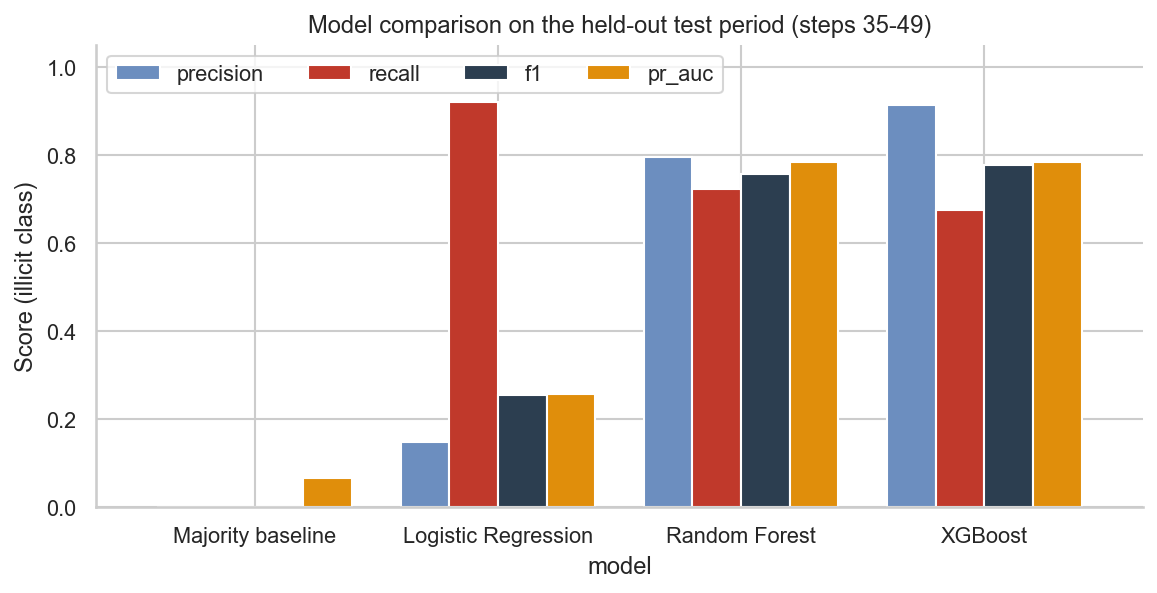

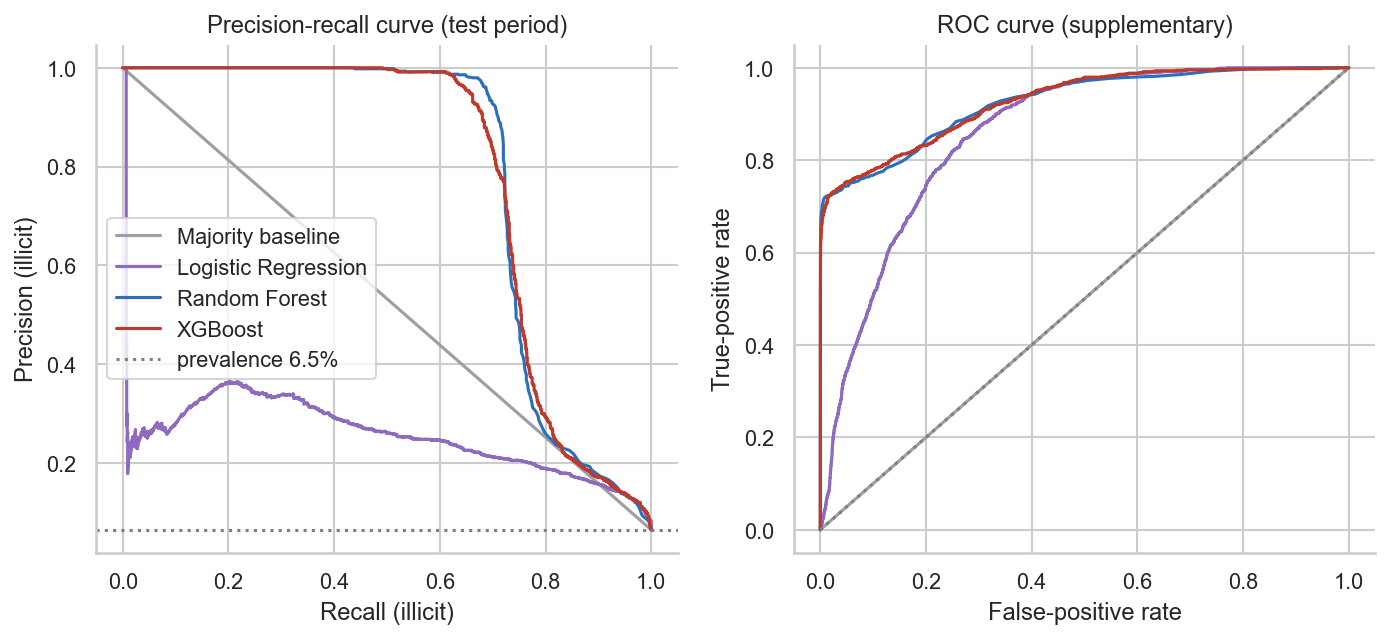

In [5]:
show("eval_03_model_comparison", 800); show("eval_01_pr_roc_curves", 1000)

**Insight.** The precision-recall curves of Random Forest and XGBoost overlap almost entirely and sit far above the linear model and the prevalence line (6.5% illicit in the test period); ROC curves look good for all models (AUC 0.86-0.93) even where the precision is poor, which is why ROC is only supplementary on imbalanced data.

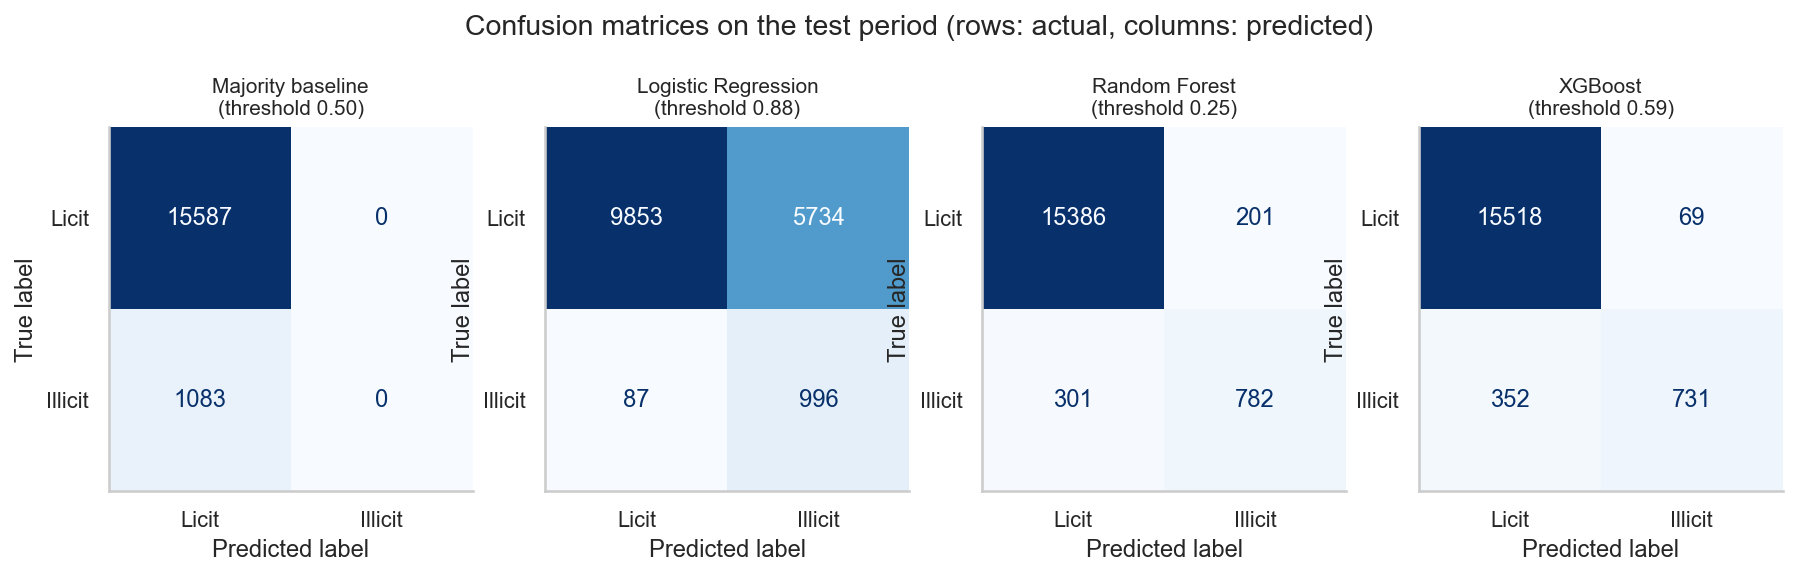

In [6]:
show("eval_02_confusion_matrices", 1100)

**Insight (false positives vs false negatives).** A false negative is a missed illicit transaction, a false positive is a wrongly flagged innocent one. Logistic Regression buys a few extra detections with thousands of false alarms; Random Forest and XGBoost sit at different points of the same trade-off (RF: 201 FP / 301 FN; XGBoost: 69 FP / 352 FN). Which is better depends on the cost of an investigator's time versus the cost of missing crime.

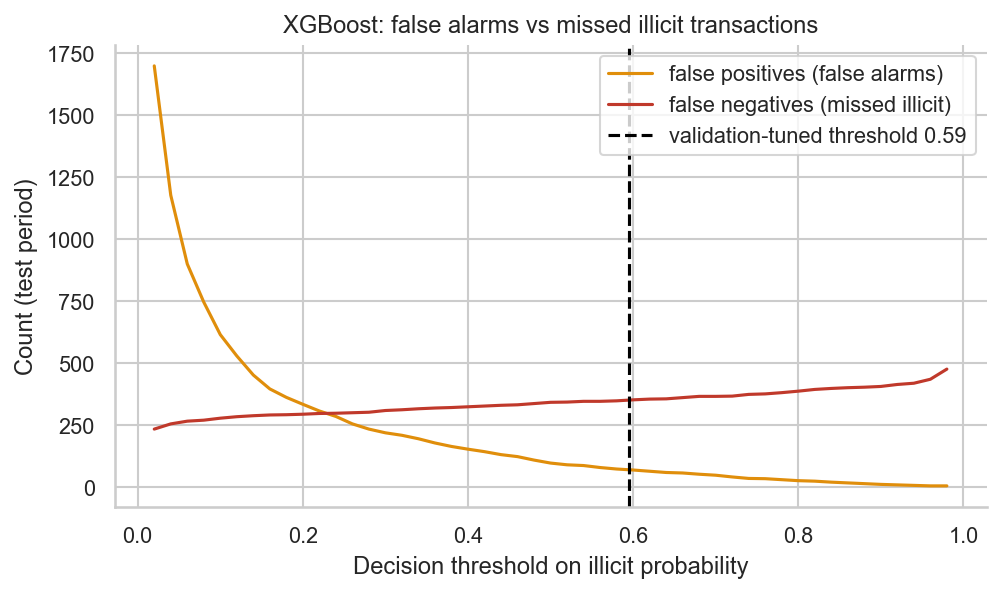

In [7]:
show("eval_05_threshold_tradeoff", 650)

**Insight.** Raising the threshold reduces false alarms and increases misses, and vice versa. The validation-tuned threshold (dashed) is a compromise that maximises F1; an investigator team with limited capacity might choose a higher threshold, a compliance team that cannot tolerate misses a lower one.

### Research question 1: how much does a random split overstate performance?

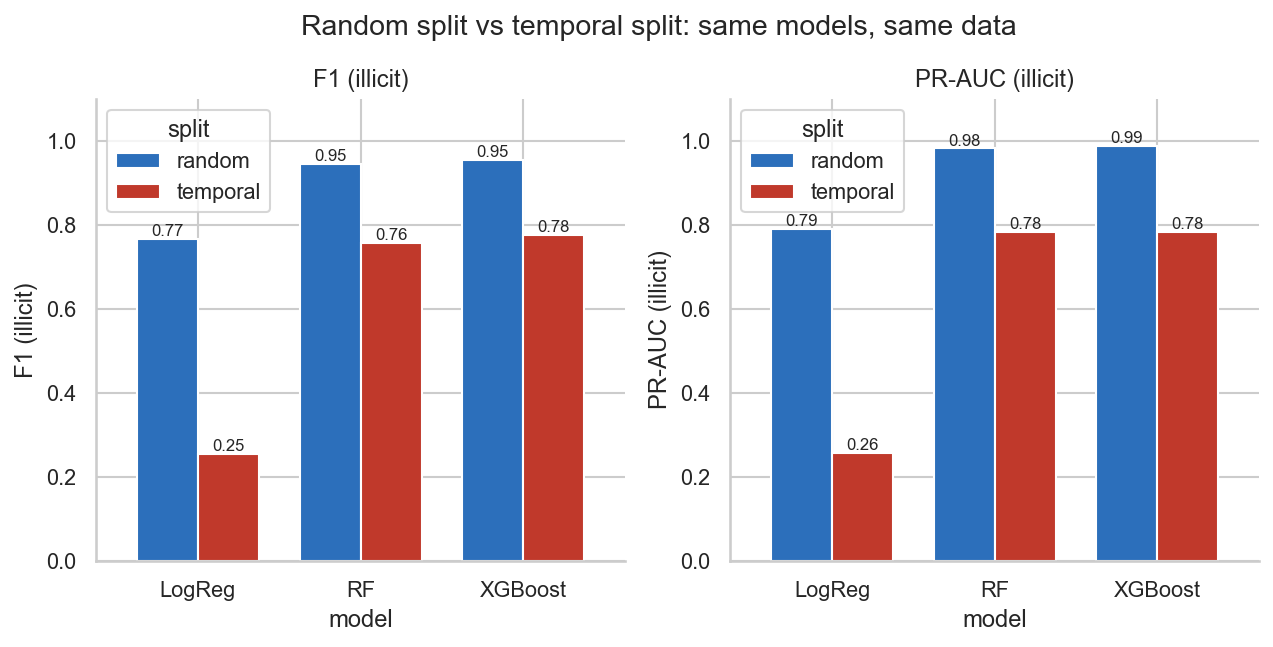

f1          pr_auc         
split  random temporal random temporal
model                                 
logreg  0.766    0.255  0.789    0.257
rf      0.945    0.757  0.982    0.784
xgb     0.955    0.776  0.988    0.783

In [8]:
rt = pd.read_csv(RES / "random_vs_temporal.csv")
show("eval_04_random_vs_temporal", 850)
rt.pivot(index="model", columns="split", values=["f1", "pr_auc"]).round(3)

**Insight.** With *identical* models and the same labelled data, a random split reports F1 0.945 (Random Forest) and 0.955 (XGBoost) against 0.757 and 0.776 for the chronological split, and PR-AUC 0.98-0.99 against 0.78. Logistic Regression drops from 0.77 to 0.26. A random split lets transactions from the same period (and their strongly related neighbours) appear in both training and test data, so the model is graded on situations it has effectively seen. **The temporal split is the honest estimate**, because in deployment a model must score transactions that occur after its training data.

### Which model is best?
* **By the pre-declared validation rule: Random Forest** (highest validation PR-AUC and F1).
* **On the test period**, Random Forest and XGBoost are statistically tied on PR-AUC; XGBoost has the higher F1 and precision (fewer false alarms), Random Forest the higher recall.
* We use **XGBoost as the default model in the demo application** because it gives fewer false alarms and supports exact per-prediction feature contributions. This is a judgement made after seeing the test results; it does not change the model-selection result above, and the app offers all three models.
* Neither model should be trusted after step 43 without retraining (notebook 05).